In [1]:
import os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED        = 42
IMG_SIZE    = 64
MODEL_SIZE  = 160
BATCH_SIZE  = 128
EPOCHS      = 40
LR_BACKBONE = 5e-4
LR_HEAD     = 2e-3
WEIGHT_DECAY = 0.05
VAL_RATIO   = 0.1
PATIENCE    = 12
NUM_WORKERS = 4
EMA_DECAY   = 0.999
CUTMIX_PROB = 0.3

CLASSES = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [2]:
FER_ROOT = '/kaggle/input/datasets/msambare/fer2013'
RAF_ROOT = '/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET'

RAF_MAP = {'1': 'surprise', '2': 'fear', '3': 'disgust', '4': 'happy',
           '5': 'sad', '6': 'angry', '7': 'neutral'}

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}

def scan(root, split, source, mapping=None):
    rows = []
    for cls_dir in sorted((Path(root) / split).iterdir()):
        if not cls_dir.is_dir():
            continue
        name = mapping[cls_dir.name] if mapping else cls_dir.name.lower()
        for f in cls_dir.iterdir():
            if f.suffix.lower() in IMG_EXT:
                rows.append((str(f), CLASSES.index(name), source))
    return pd.DataFrame(rows, columns=['path', 'label', 'source'])

fer_train = scan(FER_ROOT, 'train', 'fer')
fer_test  = scan(FER_ROOT, 'test',  'fer')
raf_train = scan(RAF_ROOT, 'train', 'raf', RAF_MAP)
raf_test  = scan(RAF_ROOT, 'test',  'raf', RAF_MAP)

print('FER train:', len(fer_train), '| FER test:', len(fer_test))
print('RAF train:', len(raf_train), '| RAF test:', len(raf_test))

FER train: 28709 | FER test: 7178
RAF train: 12271 | RAF test: 3068


In [3]:
pool = pd.concat([fer_train, raf_train, raf_test], ignore_index=True)
test_df = fer_test.reset_index(drop=True)

strat_key = pool['label'].astype(str) + '_' + pool['source']
train_df, val_df = train_test_split(
    pool, test_size=VAL_RATIO, stratify=strat_key, random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test (FER2013 test): {len(test_df)}')

# Phân bố lớp
dist = pd.DataFrame({
    'train': train_df.label.value_counts().sort_index(),
    'val':   val_df.label.value_counts().sort_index(),
    'test':  test_df.label.value_counts().sort_index(),
})
dist.index = CLASSES
display(dist)

Train: 39643 | Val: 4405 | Test (FER2013 test): 7178


,train,val,test
angry,4376,486,958
disgust,1181,132,111
fear,4007,445,1024
happy,11854,1318,1774
neutral,7353,816,1233
sad,6561,729,1247
surprise,4311,479,831


In [4]:
import gc
from concurrent.futures import ThreadPoolExecutor

def load_img(p):
    return np.asarray(Image.open(p).convert('L').resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC))

class CachedDataset(Dataset):
    def __init__(self, df, transform, desc=''):
        paths = df['path'].tolist()
        with ThreadPoolExecutor(8) as ex:
            imgs = list(tqdm(ex.map(load_img, paths), total=len(paths), desc=desc, leave=False))
        self.imgs = np.stack(imgs)
        self.labels = df['label'].values
        self.transform = transform
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.imgs[i])), int(self.labels[i])

train_tf = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=12, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(),
    T.Normalize([0.5], [0.5]),
    T.RandomErasing(p=0.25, scale=(0.02, 0.1)),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5], [0.5]),
])

train_ds = CachedDataset(train_df, train_tf, 'cache train')
val_ds   = CachedDataset(val_df,   eval_tf,  'cache val')
test_ds  = CachedDataset(test_df,  eval_tf,  'cache test')

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                          persistent_workers=(NUM_WORKERS > 0))
val_loader   = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

gc.collect()

cache train:   0%|          | 0/39643 [00:00<?, ?it/s]

cache val:   0%|          | 0/4405 [00:00<?, ?it/s]

cache test:   0%|          | 0/7178 [00:00<?, ?it/s]

28

In [5]:
import torch.nn.functional as F
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

class EmotionEffNet(nn.Module):
    def __init__(self, num_classes=7, pretrained=True, drop=0.3, drop_path=0.1, size=MODEL_SIZE):
        super().__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        net = efficientnet_b0(weights=weights, stochastic_depth_prob=drop_path)

        old = net.features[0][0]
        new = nn.Conv2d(1, old.out_channels, old.kernel_size, old.stride, old.padding, bias=False)
        with torch.no_grad():
            new.weight.copy_(old.weight.sum(dim=1, keepdim=True))
        net.features[0][0] = new

        net.classifier = nn.Sequential(nn.Dropout(drop), nn.Linear(net.classifier[1].in_features, num_classes))

        self.net, self.size = net, size

    def forward(self, x):
        x = x * 0.5 + 0.5
        x = (x - 0.449) / 0.226
        if x.shape[-1] != self.size:
            x = F.interpolate(x, size=(self.size, self.size), mode='bilinear', align_corners=False)
        return self.net(x)

model = EmotionEffNet(len(CLASSES)).to(device).to(memory_format=torch.channels_last)
print(f'Params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 139MB/s] 


Params: 4.02M


In [6]:
import copy

use_amp = (device.type == 'cuda')

counts  = np.bincount(train_df['label'].values, minlength=len(CLASSES))
weights = (counts.sum() / (len(CLASSES) * counts)) ** 0.5
weights = torch.tensor(weights, dtype=torch.float32, device=device)
print('Class weights:', dict(zip(CLASSES, weights.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.05)

param_groups = []
for part, lr in [('backbone', LR_BACKBONE), ('head', LR_HEAD)]:
    ps = [(n, p) for n, p in model.named_parameters()
          if n.startswith('net.classifier') == (part == 'head')]
    param_groups += [
        {'params': [p for n, p in ps if p.ndim > 1],  'lr': lr, 'weight_decay': WEIGHT_DECAY},
        {'params': [p for n, p in ps if p.ndim <= 1], 'lr': lr, 'weight_decay': 0.0},
    ]
optimizer = torch.optim.AdamW(param_groups)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=[g['lr'] for g in param_groups], epochs=EPOCHS,
    steps_per_epoch=len(train_loader), pct_start=0.15)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

class ModelEMA:
    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.updates = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])
ema = ModelEMA(model, EMA_DECAY)

def cutmix(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    H, W = x.shape[2:]
    r = np.sqrt(1 - lam)
    ch, cw = int(H * r), int(W * r)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - ch // 2, 0, H), np.clip(cy + ch // 2, 0, H)
    x1, x2 = np.clip(cx - cw // 2, 0, W), np.clip(cx + cw // 2, 0, W)
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    return x, y, y[idx], lam

def to_dev(x, y):
    return (x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last),
            y.to(device, non_blocking=True))

def train_one_epoch(model, loader, mix_on):
    model.train()
    total_loss, correct, n = 0.0, 0.0, 0
    for x, y in tqdm(loader, leave=False, desc='train'):
        x, y = to_dev(x, y)
        use_mix = mix_on and np.random.rand() < CUTMIX_PROB
        if use_mix:
            x, ya, yb, lam = cutmix(x, y)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
            loss = (lam * criterion(out, ya) + (1 - lam) * criterion(out, yb)) if use_mix \
                   else criterion(out, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer); scaler.update()
        scheduler.step()
        ema.update(model)

        pred = out.argmax(1)
        c = (lam * (pred == ya).float().sum() + (1 - lam) * (pred == yb).float().sum()) if use_mix \
            else (pred == y).float().sum()
        total_loss += loss.item() * x.size(0); correct += c.item(); n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in tqdm(loader, leave=False, desc='eval'):
        x, y = to_dev(x, y)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
            loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        preds = out.argmax(1)
        correct += (preds == y).sum().item(); n += x.size(0)
        all_preds.append(preds.cpu()); all_labels.append(y.cpu())
    return (total_loss / n, correct / n,
            torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy())

Class weights: {'angry': np.float32(1.14), 'disgust': np.float32(2.19), 'fear': np.float32(1.19), 'happy': np.float32(0.69), 'neutral': np.float32(0.88), 'sad': np.float32(0.93), 'surprise': np.float32(1.15)}


In [7]:
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_fer_acc': []}
fer_mask = (val_df['source'].values == 'fer')
best_fer_acc, best_epoch, bad_epochs = 0.0, 0, 0
BEST_PATH = '/kaggle/working/best_model.pth'

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    mix_on = epoch <= EPOCHS - 5
    tr_loss, tr_acc = train_one_epoch(model, train_loader, mix_on)
    va_loss, va_acc, vp, vl = evaluate(ema.module, val_loader)
    fer_acc = float((vp[fer_mask] == vl[fer_mask]).mean())

    history['train_loss'].append(tr_loss); history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc);   history['val_acc'].append(va_acc)
    history['val_fer_acc'].append(fer_acc)

    flag = ''
    if fer_acc > best_fer_acc:
        best_fer_acc, best_epoch, bad_epochs = fer_acc, epoch, 0
        torch.save(ema.module.state_dict(), BEST_PATH)
        flag = '  <-- best'
    else:
        bad_epochs += 1

    print(f'Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | '
          f'val(EMA) loss {va_loss:.4f} acc {va_acc:.4f} | val-FER acc {fer_acc:.4f} | '
          f'{time.time()-t0:.0f}s{flag}')

    if bad_epochs >= PATIENCE:
        print(f'Early stopping tại epoch {epoch}. Best epoch {best_epoch} (val-FER {best_fer_acc:.4f})')
        break

train:   0%|          | 0/309 [00:00<?, ?it/s]

eval:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 01/40 | train loss 1.8248 acc 0.3400 | val(EMA) loss 1.5993 acc 0.4783 | val-FER acc 0.4486 | 77s  <-- best


train:   0%|          | 0/309 [00:00<?, ?it/s]

eval:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 02/40 | train loss 1.5380 acc 0.4931 | val(EMA) loss 1.3000 acc 0.5984 | val-FER acc 0.5639 | 50s  <-- best


... (83 outputs left out)

Epoch 30/40 | train loss 0.6546 acc 0.8694 | val(EMA) loss 1.0109 acc 0.7578 | val-FER acc 0.7099 | 52s


train:   0%|          | 0/309 [00:00<?, ?it/s]

eval:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 31/40 | train loss 0.6562 acc 0.8678 | val(EMA) loss 1.0159 acc 0.7569 | val-FER acc 0.7081 | 52s
Early stopping tại epoch 31. Best epoch 19 (val-FER 0.7196)


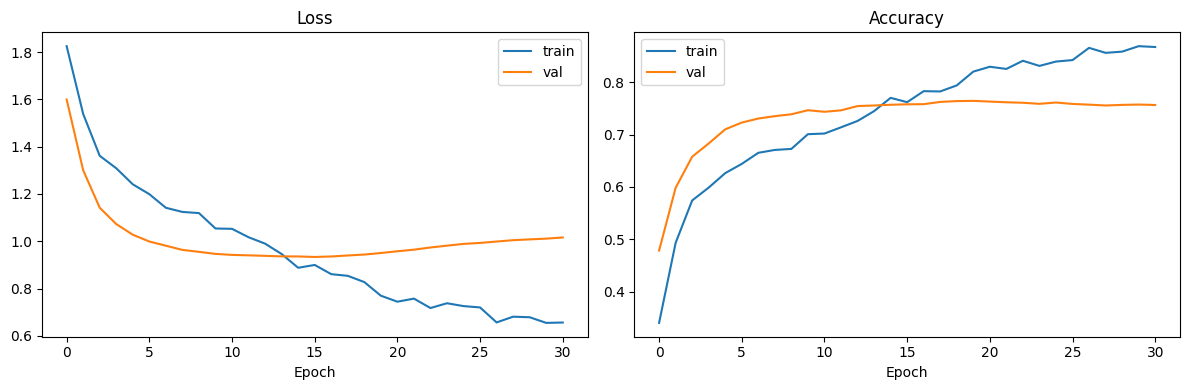

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(history['train_loss'], label='train'); axs[0].plot(history['val_loss'], label='val')
axs[0].set_title('Loss'); axs[0].set_xlabel('Epoch'); axs[0].legend()
axs[1].plot(history['train_acc'], label='train'); axs[1].plot(history['val_acc'], label='val')
axs[1].set_title('Accuracy'); axs[1].set_xlabel('Epoch'); axs[1].legend()
plt.tight_layout(); plt.show()

Test FER2013 | không TTA: 0.7171 | có TTA (flip): 0.7204

              precision    recall  f1-score   support

       angry     0.6231    0.7025    0.6605       958
     disgust     0.8265    0.7297    0.7751       111
        fear     0.5978    0.5342    0.5642      1024
       happy     0.9012    0.9002    0.9007      1774
     neutral     0.6505    0.7502    0.6968      1233
         sad     0.6371    0.5293    0.5782      1247
    surprise     0.8047    0.8279    0.8161       831

    accuracy                         0.7204      7178
   macro avg     0.7201    0.7106    0.7131      7178
weighted avg     0.7195    0.7204    0.7179      7178



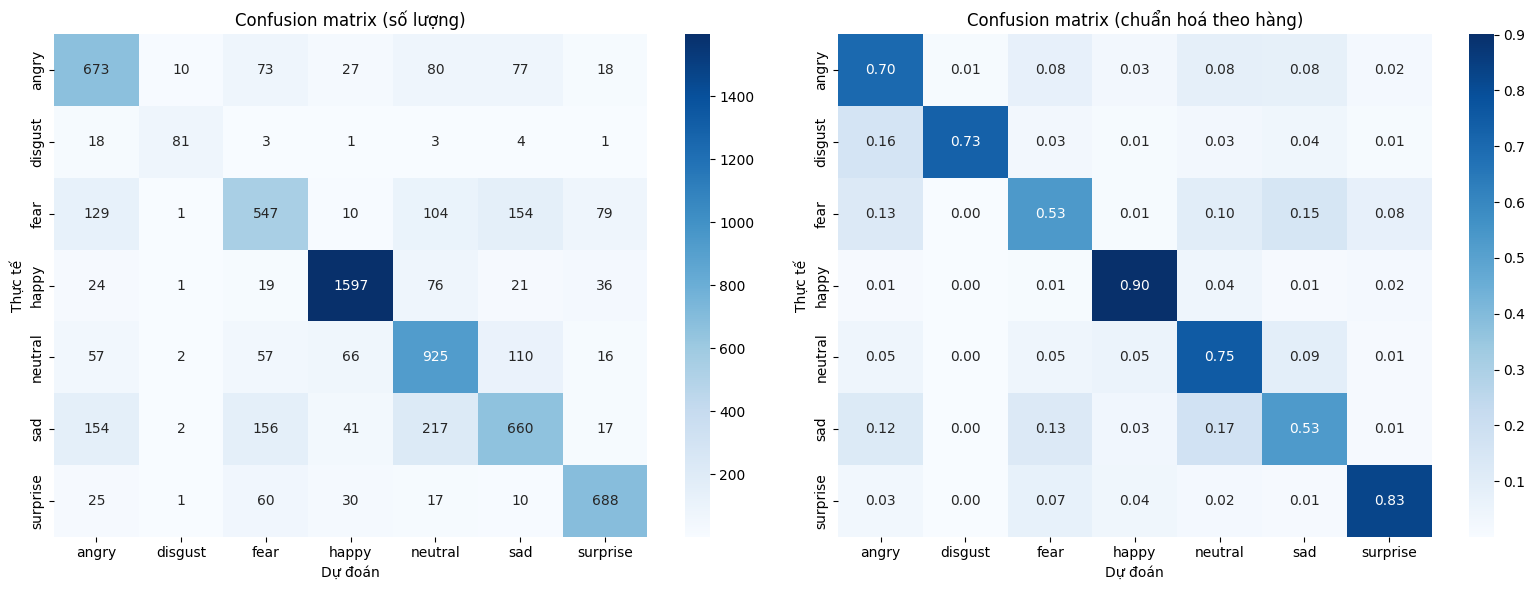

In [9]:
best_model = EmotionEffNet(len(CLASSES), pretrained=False).to(device).to(memory_format=torch.channels_last)
best_model.load_state_dict(torch.load(BEST_PATH, map_location=device))
best_model.eval()

@torch.no_grad()
def predict_proba_tta(model, loader, tta=True):
    model.eval()
    out = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            p = torch.softmax(model(x).float(), 1)
            if tta:
                p = (p + torch.softmax(model(torch.flip(x, dims=[3])).float(), 1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

labels = test_df['label'].values
acc_plain = (predict_proba_tta(best_model, test_loader, tta=False).argmax(1) == labels).mean()
probs     = predict_proba_tta(best_model, test_loader, tta=True)
preds     = probs.argmax(1)
print(f'Test FER2013 | không TTA: {acc_plain:.4f} | có TTA (flip): {(preds == labels).mean():.4f}\n')

print(classification_report(labels, preds, target_names=CLASSES, digits=4))

cm = confusion_matrix(labels, preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=axs[0])
axs[0].set_title('Confusion matrix (số lượng)')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=axs[1])
axs[1].set_title('Confusion matrix (chuẩn hoá theo hàng)')
for ax in axs:
    ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
plt.tight_layout(); plt.show()

model = best_model

In [10]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()

def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()

@torch.no_grad()
def benchmark(batch_size, n_iter=200, warmup=30, amp=False):
    x = torch.randn(batch_size, 1, IMG_SIZE, IMG_SIZE, device=device)
    with torch.autocast(device_type=device.type, enabled=(amp and device.type == 'cuda')):
        for _ in range(warmup):
            model(x)
        sync()
        t0 = time.perf_counter()
        for _ in range(n_iter):
            model(x)
        sync()
        dt = time.perf_counter() - t0
    return batch_size * n_iter / dt, dt / n_iter * 1000

rows = []
for bs in [1, 32, 128, 512]:
    for amp in [False, True]:
        if amp and device.type != 'cuda':
            continue
        fps, ms = benchmark(bs, amp=amp)
        rows.append({'batch_size': bs, 'precision': 'FP16 (AMP)' if amp else 'FP32',
                     'FPS': round(fps, 1), 'ms / batch': round(ms, 2)})
fps_df = pd.DataFrame(rows)
print(f'Thiết bị: {torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"}')
display(fps_df)

@torch.no_grad()
def benchmark_e2e(paths, warmup=20):
    for p in paths[:warmup]:
        model(eval_tf(Image.open(p).convert('L')).unsqueeze(0).to(device))
    sync()
    t0 = time.perf_counter()
    for p in paths:
        x = eval_tf(Image.open(p).convert('L')).unsqueeze(0).to(device)
        model(x).argmax(1).item()
    sync()
    return len(paths) / (time.perf_counter() - t0)

sample_paths = test_df['path'].sample(500, random_state=SEED).tolist()
e2e_fps = benchmark_e2e(sample_paths)
print(f'\nEnd-to-end (batch=1, gồm đọc ảnh + tiền xử lý): {e2e_fps:.1f} FPS '
      f'(~{1000/e2e_fps:.2f} ms/ảnh)')

n_params = sum(p.numel() for p in model.parameters())
size_mb = os.path.getsize(BEST_PATH) / 1024**2
print(f'Params: {n_params/1e6:.2f}M | Kích thước file: {size_mb:.1f} MB')

Thiết bị: Tesla T4


,batch_size,precision,FPS,ms / batch
0,1,FP32,106.9,9.35
1,1,FP16 (AMP),110.5,9.05
2,32,FP32,1656.2,19.32
3,32,FP16 (AMP),3148.4,10.16
4,128,FP32,1413.8,90.54
5,128,FP16 (AMP),2697.0,47.46
6,512,FP32,1527.3,335.22
7,512,FP16 (AMP),2742.5,186.69



End-to-end (batch=1, gồm đọc ảnh + tiền xử lý): 62.5 FPS (~16.01 ms/ảnh)
Params: 4.02M | Kích thước file: 15.6 MB


Số ảnh dự đoán sai: 2030 / 7178 (28.28%)


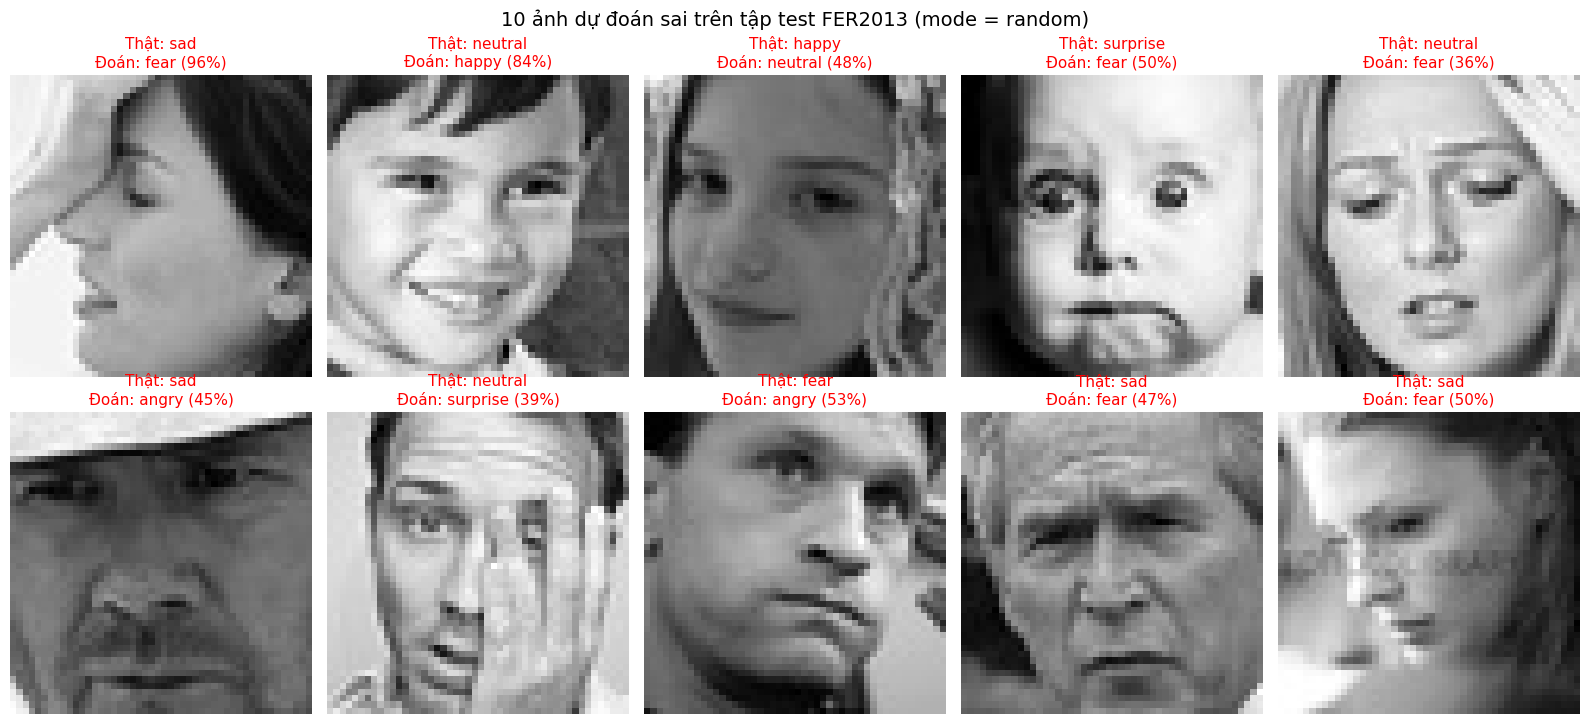

,path,thật,đoán,độ tin cậy
0,PublicTest_28848037.jpg,sad,fear,95.6%
1,PublicTest_73189561.jpg,neutral,happy,84.0%
2,PublicTest_49174878.jpg,happy,neutral,47.8%
3,PublicTest_35396845.jpg,surprise,fear,50.2%
4,PublicTest_55088612.jpg,neutral,fear,36.2%
5,PublicTest_66693020.jpg,sad,angry,45.3%
6,PublicTest_63454133.jpg,neutral,surprise,39.4%
7,PrivateTest_86819061.jpg,fear,angry,53.3%
8,PrivateTest_70717012.jpg,sad,fear,47.1%
9,PrivateTest_92872267.jpg,sad,fear,50.0%


In [11]:
MODE = 'random'
N_SHOW = 10

@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    probs = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True)
        probs.append(torch.softmax(model(x).float(), dim=1).cpu())
    return torch.cat(probs).numpy()

probs = predict_proba(model, test_loader)
preds = probs.argmax(1)
labels = test_df['label'].values
conf = probs.max(1)

wrong_idx = np.where(preds != labels)[0]
print(f'Số ảnh dự đoán sai: {len(wrong_idx)} / {len(labels)} '
      f'({len(wrong_idx)/len(labels)*100:.2f}%)')

if MODE == 'confident':
    chosen = wrong_idx[np.argsort(-conf[wrong_idx])[:N_SHOW]]
else:
    chosen = np.random.RandomState(SEED).choice(wrong_idx, N_SHOW, replace=False)

fig, axs = plt.subplots(2, 5, figsize=(16, 7.5))
for ax, i in zip(axs.ravel(), chosen):
    img = Image.open(test_df.loc[i, 'path']).convert('L')
    ax.imshow(img, cmap='gray')
    ax.set_title(f'Thật: {CLASSES[labels[i]]}\n'
                 f'Đoán: {CLASSES[preds[i]]} ({conf[i]*100:.0f}%)',
                 color='red', fontsize=11)
    ax.axis('off')
plt.suptitle(f'10 ảnh dự đoán sai trên tập test FER2013 (mode = {MODE})', fontsize=14)
plt.tight_layout(); plt.show()

display(pd.DataFrame({
    'path': [Path(test_df.loc[i, 'path']).name for i in chosen],
    'thật': [CLASSES[labels[i]] for i in chosen],
    'đoán': [CLASSES[preds[i]] for i in chosen],
    'độ tin cậy': [f'{conf[i]*100:.1f}%' for i in chosen],
}))